# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [1]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [2]:
# Inspect the shapes of the datasets
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)
print("y_train one-hot shape:", y_train.shape)

X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)
y_train one-hot shape: (60000, 10)


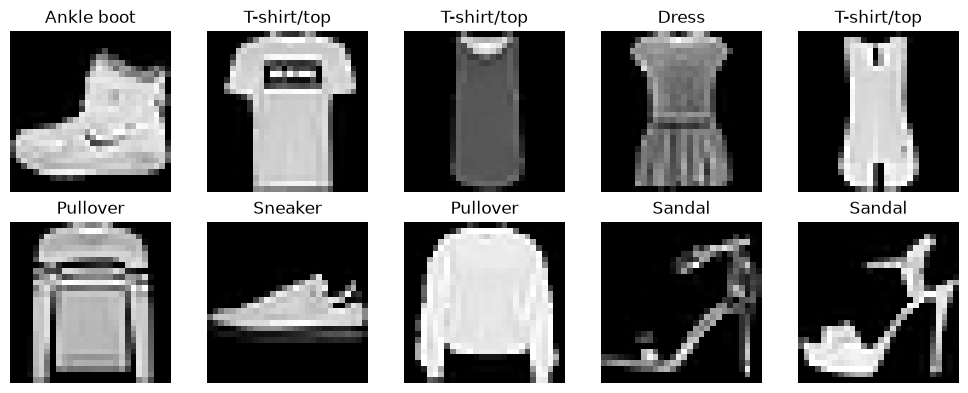

In [5]:
import matplotlib.pyplot as plt
import numpy as np
# Verify the data looks as expected
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[np.argmax(y_train[i])])
    plt.axis('off')
plt.tight_layout()
plt.show()

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

Yes, the data looks as expected, with each clothing image properly matched to its label. The image quality is low resolution, so the items are recognizable overall, though the edges and fine details are pixelated. Besides the images being pixelated, I don't think there are any other issues.

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [6]:
from keras.models import Sequential
from keras.layers import Dense, Flatten
from tensorflow.keras.losses import CategoricalCrossentropy

# Create a simple linear regression model
model = Sequential()
# You can use `model.add(<layer>)` to add layers to the model
model.add(Flatten(input_shape=(28, 28)))  
model.add(Dense(10))

# Compile the model using `model.compile()`
model.compile(optimizer='adam', loss=CategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

# Train the model with `model.fit()`
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1)

# Evaluate the model with `model.evaluate()`
base_loss, base_accuracy = model.evaluate(X_test, y_test)
print(f"Baseline Test Accuracy: {base_accuracy:.4f}")

c:\Users\molly\Desktop\DSI\repos\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 61s 27ms/step - accuracy: 0.7915 - loss: 0.6192 - val_accuracy: 0.8345 - val_loss: 0.4811
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 59s 13ms/step - accuracy: 0.8404 - loss: 0.4679 - val_accuracy: 0.8447 - val_loss: 0.4471
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8487 - loss: 0.4405 - val_accuracy: 0.8437 - val_loss: 0.4433
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8541 - loss: 0.4263 - val_accuracy: 0.8488 - val_loss: 0.4250
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8562 - loss: 0.4165 - val_accuracy: 0.8543 - val_loss: 0.4213
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8593 - loss: 0.4087 - val_accuracy: 0.8563 - val_loss: 0.4218
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8601 - loss: 0.4037 - val_accuracy: 0.8440 - val_loss: 0.4391
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8624 - loss: 0.399

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

The baseline model achieved a test accuracy of 84.47%. This matches what I expected, it is much better than random guessing, though limited compared to deeper vision models. Performance stays at this level because flattening the 28x28 images removes 2D spatial structure, and using only a single linear layer without hidden layers means the model can only learn linear boundaries and struggles to separate visually similar clothing categories.

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [7]:
from keras.layers import Conv2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
history_cnn = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1)

# Evaluate the model
cnn_loss, cnn_accuracy = model.evaluate(X_test, y_test)
print(f"Simple CNN Test Accuracy: {cnn_accuracy:.4f}")


c:\Users\molly\Desktop\DSI\repos\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 38s 21ms/step - accuracy: 0.8548 - loss: 0.4067 - val_accuracy: 0.8887 - val_loss: 0.3188
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 36s 21ms/step - accuracy: 0.9022 - loss: 0.2692 - val_accuracy: 0.8947 - val_loss: 0.2917
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 33s 20ms/step - accuracy: 0.9196 - loss: 0.2197 - val_accuracy: 0.9018 - val_loss: 0.2748
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 32s 19ms/step - accuracy: 0.9338 - loss: 0.1814 - val_accuracy: 0.9013 - val_loss: 0.2997
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 50s 30ms/step - accuracy: 0.9448 - loss: 0.1519 - val_accuracy: 0.9042 - val_loss: 0.2957
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 51s 30ms/step - accuracy: 0.9537 - loss: 0.1241 - val_accuracy: 0.9020 - val_loss: 0.3089
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 73s 43ms/step - accuracy: 0.9625 - loss: 0.1025 - val_accuracy: 0.9020 - val_loss: 0.3315
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 64s 38ms/step - accuracy: 0.9695 -

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

The CNN performed better than the baseline model. Test accuracy improved by 5.16%, increasing from 84.47% to 89.63%. It performed better because the convolutional layer preserves the 2D spatial layout of the images and learns local visual features, while the ReLU hidden layer allows the network to capture non-linear patterns instead of relying on a single linear boundary.

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

Training with 16 filters...


Filters: 16 -> Test Accuracy: 0.8993
Training with 32 filters...
Filters: 32 -> Test Accuracy: 0.9047
Training with 64 filters...
Filters: 64 -> Test Accuracy: 0.8998


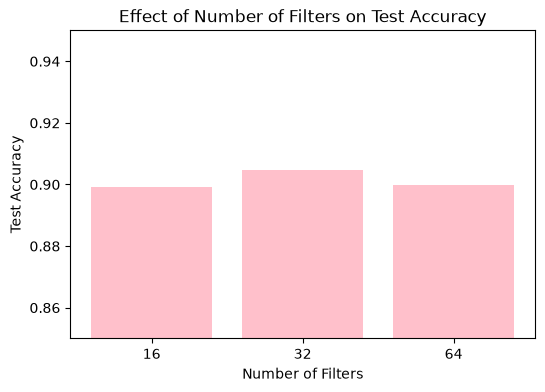

In [13]:
# A. Test Hyperparameters
filter_options = [16, 32, 64]
filter_results = {}
for filters in filter_options:
    print(f"Training with {filters} filters...")
    exp_model = Sequential([
        Conv2D(filters, (3, 3), activation='relu', input_shape=(28, 28, 1)),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')])
    exp_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    exp_model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.1, verbose=0)
    test_acc = exp_model.evaluate(X_test, y_test, verbose=0)[1]
    filter_results[filters] = test_acc
    print(f"Filters: {filters} -> Test Accuracy: {test_acc:.4f}")

# Plot results
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.bar([str(f) for f in filter_results.keys()], filter_results.values(), color='pink')
plt.xlabel("Number of Filters")
plt.ylabel("Test Accuracy")
plt.title("Effect of Number of Filters on Test Accuracy")
plt.ylim(0.85, 0.95)
plt.show()

Training Without Dropout...
Regularization: Without Dropout -> Test Accuracy: 0.9010
Training With Dropout...
Regularization: With Dropout -> Test Accuracy: 0.8890


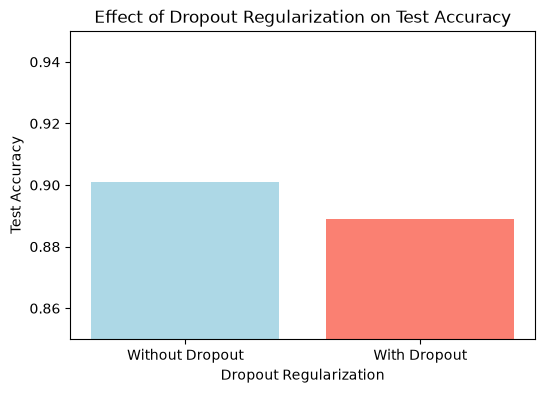

In [14]:
# B. Test presence or absence of regularization
from keras.layers import Dropout
reg_options = [False, True]
reg_results = {}
for use_dropout in reg_options:
    label = "With Dropout" if use_dropout else "Without Dropout"
    print(f"Training {label}...")

    exp_model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
        Flatten(),
        Dense(64, activation='relu')])
    if use_dropout:
        exp_model.add(Dropout(0.5))
    exp_model.add(Dense(10, activation='softmax'))
    exp_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    exp_model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.1, verbose=0)
    test_acc = exp_model.evaluate(X_test, y_test, verbose=0)[1]
    reg_results[label] = test_acc
    print(f"Regularization: {label} -> Test Accuracy: {test_acc:.4f}")

# Plot results
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.bar(reg_results.keys(), reg_results.values(), color=['lightblue', 'salmon'])
plt.ylabel("Test Accuracy")
plt.xlabel("Dropout Regularization")
plt.title("Effect of Dropout Regularization on Test Accuracy")
plt.ylim(0.85, 0.95)
plt.show()

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

For the hyperparameters, 32 filters achieved the highest test accuracy at 90.47%, slightly outperforming 16 filters at 89.93% and 64 filters at 89.98%. All three numbers are close in range, which shows that changing the number of filters doesn't make a huge difference for this model. For regularization, the model without dropout performed better, 90.10%, than the model with dropout, 88.90%. Adding dropout likely deactivated too many connections for a short 5-epoch training run, which cut out useful information. Based on these experiments, using 32 filters without dropout gave the best overall performance.


# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [15]:
final_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')])
final_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_final = final_model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1)
final_loss, final_accuracy = final_model.evaluate(X_test, y_test)
print(f"Final Optimized Model Test Accuracy: {final_accuracy:.4f}")

c:\Users\molly\Desktop\DSI\repos\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 59s 30ms/step - accuracy: 0.8600 - loss: 0.3904 - val_accuracy: 0.8875 - val_loss: 0.3089
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 189s 112ms/step - accuracy: 0.9056 - loss: 0.2599 - val_accuracy: 0.8988 - val_loss: 0.2858
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 263s 153ms/step - accuracy: 0.9231 - loss: 0.2097 - val_accuracy: 0.8978 - val_loss: 0.2783
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 69s 38ms/step - accuracy: 0.9360 - loss: 0.1713 - val_accuracy: 0.9050 - val_loss: 0.2878
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 51s 30ms/step - accuracy: 0.9480 - loss: 0.1407 - val_accuracy: 0.9078 - val_loss: 0.2782
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 83s 49ms/step - accuracy: 0.9590 - loss: 0.1129 - val_accuracy: 0.9023 - val_loss: 0.3123
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 54s 32ms/step - accuracy: 0.9656 - loss: 0.0910 - val_accuracy: 0.9062 - val_loss: 0.3383
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 48s 28ms/step - accuracy: 0.97

Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

The final model reached a test accuracy of 90.10%, which is better than the baseline model that only got 84.47% and slightly ahead of our first CNN model which got 89.63%. Moving from a single linear layer to a network with more hidden layers allowed the model to find better patterns in the data instead of just doing a simple linear lookup. Using a hidden layer size of 32 provided a good balance for the network parameters, giving it enough capacity to learn the material without over-memorizing the training answers over the 10 epochs. If I had more time, I would test other choices mentioned in the slides, like trying the Adam optimizer with a learning rate of 3e-4 or using SGD with momentum, to see if a different update rule helps the model learn even faster.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 26/10/2025`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.